# Experiment 4: K-Nearest Neighbour (KNN) Classification on Iris Dataset

## Section 4: Setup and Data Preparation

In [18]:
# IMPORTANT: Replace 386 .
ROLL_NUMBER = 386

import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

np.random.seed(ROLL_NUMBER)

# Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=ROLL_NUMBER)

print(f"Training set size: {len(X_train)} samples")
print(f"Testing set size: {len(X_test)} samples")

Training set size: 105 samples
Testing set size: 45 samples


## Section 8: How KNN Classifies One Flower (Conceptual)

In [19]:
import matplotlib.pyplot as plt

# For demonstration, let's pick a random test sample
sample_idx = np.random.randint(0, len(X_test))
sample_to_classify = X_test[sample_idx]
sample_true_label = y_test[sample_idx]

print(f"Sample to classify: {sample_to_classify} (True label: {iris.target_names[sample_true_label]})")

# Calculate Euclidean distances to all training samples
distances = np.array([np.linalg.norm(sample_to_classify - train_sample) for train_sample in X_train])

# Find the indices of the k nearest neighbors (let's use k=5 for now)
k = 5
nearest_neighbor_indices = np.argsort(distances)[:k]

print(f"\nTop {k} nearest neighbors indices: {nearest_neighbor_indices}")
print(f"Distances to these neighbors: {distances[nearest_neighbor_indices]}")
print(f"Labels of these neighbors: {iris.target_names[y_train[nearest_neighbor_indices]]}")

# Predict the label based on the majority vote
from collections import Counter
neighbor_labels = y_train[nearest_neighbor_indices]
predicted_label = Counter(neighbor_labels).most_common(1)[0][0]

print(f"\nPredicted label for sample: {iris.target_names[predicted_label]}")
print(f"True label for sample: {iris.target_names[sample_true_label]}")

Sample to classify: [6.5 3.  5.2 2. ] (True label: virginica)

Top 5 nearest neighbors indices: [91  5 74 27 67]
Distances to these neighbors: [0.34641016 0.36055513 0.38729833 0.38729833 0.41231056]
Labels of these neighbors: ['virginica' 'virginica' 'virginica' 'virginica' 'versicolor']

Predicted label for sample: virginica
True label for sample: virginica


## Section 9: Build the Actual KNN Model

In [20]:
# Initialize the KNeighborsClassifier model (using k=5 as an example)
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_model.fit(X_train, y_train)

print("KNN model trained successfully with k=5.")

KNN model trained successfully with k=5.


## Section 10: Print Correct and Wrong Predictions

In [21]:
# Make predictions on the test set
y_pred = knn_model.predict(X_test)

correct_predictions = []
wrong_predictions = []

for i in range(len(y_test)):
    true_label_name = iris.target_names[y_test[i]]
    predicted_label_name = iris.target_names[y_pred[i]]

    if y_test[i] == y_pred[i]:
        correct_predictions.append({
            'sample_index': i,
            'features': X_test[i],
            'true_label': true_label_name,
            'predicted_label': predicted_label_name
        })
    else:
        wrong_predictions.append({
            'sample_index': i,
            'features': X_test[i],
            'true_label': true_label_name,
            'predicted_label': predicted_label_name
        })

print(f"Total test samples: {len(y_test)}")
print(f"Correct predictions: {len(correct_predictions)}")
print(f"Wrong predictions: {len(wrong_predictions)}")

print("\n--- Correct Predictions ---")
if correct_predictions:
    for pred in correct_predictions:
        print(f"Sample {pred['sample_index']}: Features={pred['features']}, True={pred['true_label']}, Predicted={pred['predicted_label']}")
else:
    print("No correct predictions found.")

print("\n--- Wrong Predictions ---")
if wrong_predictions:
    for pred in wrong_predictions:
        print(f"Sample {pred['sample_index']}: Features={pred['features']}, True={pred['true_label']}, Predicted={pred['predicted_label']}")
else:
    print("No wrong predictions found.")

Total test samples: 45
Correct predictions: 43
Wrong predictions: 2

--- Correct Predictions ---
Sample 0: Features=[4.6 3.4 1.4 0.3], True=setosa, Predicted=setosa
Sample 1: Features=[5.1 2.5 3.  1.1], True=versicolor, Predicted=versicolor
Sample 2: Features=[5.1 3.8 1.5 0.3], True=setosa, Predicted=setosa
Sample 3: Features=[6.3 2.7 4.9 1.8], True=virginica, Predicted=virginica
Sample 4: Features=[6.7 3.3 5.7 2.1], True=virginica, Predicted=virginica
Sample 5: Features=[6.2 2.8 4.8 1.8], True=virginica, Predicted=virginica
Sample 6: Features=[6.  2.2 4.  1. ], True=versicolor, Predicted=versicolor
Sample 8: Features=[5.5 3.5 1.3 0.2], True=setosa, Predicted=setosa
Sample 9: Features=[7.  3.2 4.7 1.4], True=versicolor, Predicted=versicolor
Sample 10: Features=[6.8 2.8 4.8 1.4], True=versicolor, Predicted=versicolor
Sample 11: Features=[5.8 2.6 4.  1.2], True=versicolor, Predicted=versicolor
Sample 12: Features=[5.7 3.  4.2 1.2], True=versicolor, Predicted=versicolor
Sample 13: Feature

## Section 11: Model Evaluation

In [22]:
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy: 0.96

Confusion Matrix:
[[14  0  0]
 [ 0 16  1]
 [ 0  1 13]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        14
  versicolor       0.94      0.94      0.94        17
   virginica       0.93      0.93      0.93        14

    accuracy                           0.96        45
   macro avg       0.96      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45



## Section 12: Decision Boundary Visualization

To visualize the decision boundaries, we will reduce the features to two dimensions (Petal Length and Petal Width) as it's easier to plot. We will then plot the decision boundaries for different values of K.

In [23]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# For visualization, let's use only two features: Petal Length and Petal Width
X_vis = iris.data[:, 2:]  # Petal length and Petal width
y_vis = iris.target

# Split for visualization (can use a simplified split or the original, but for consistency let's use a new one)
X_train_vis, X_test_vis, y_train_vis, y_test_vis = train_test_split(X_vis, y_vis, test_size=0.3, random_state=ROLL_NUMBER)

# Create color maps for visualization
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

def plot_decision_boundary(X, y, classifier, title, ax):
    # Plot the decision boundary. For that, we will assign a color to each
    # point in the mesh [x_min, x_max]x[y_min, y_max].
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))
    Z = classifier.predict(np.c_[xx.ravel(), yy.ravel()])

    # Put the result into a color plot
    Z = Z.reshape(xx.shape)
    ax.pcolormesh(xx, yy, Z, cmap=cmap_light, alpha=0.8)

    # Plot also the training points
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_bold, edgecolor='k', s=20)
    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())
    ax.set_title(title)
    ax.set_xlabel(iris.feature_names[2]) # Petal Length
    ax.set_ylabel(iris.feature_names[3]) # Petal Width

print("Setup complete for decision boundary visualization.")

Setup complete for decision boundary visualization.


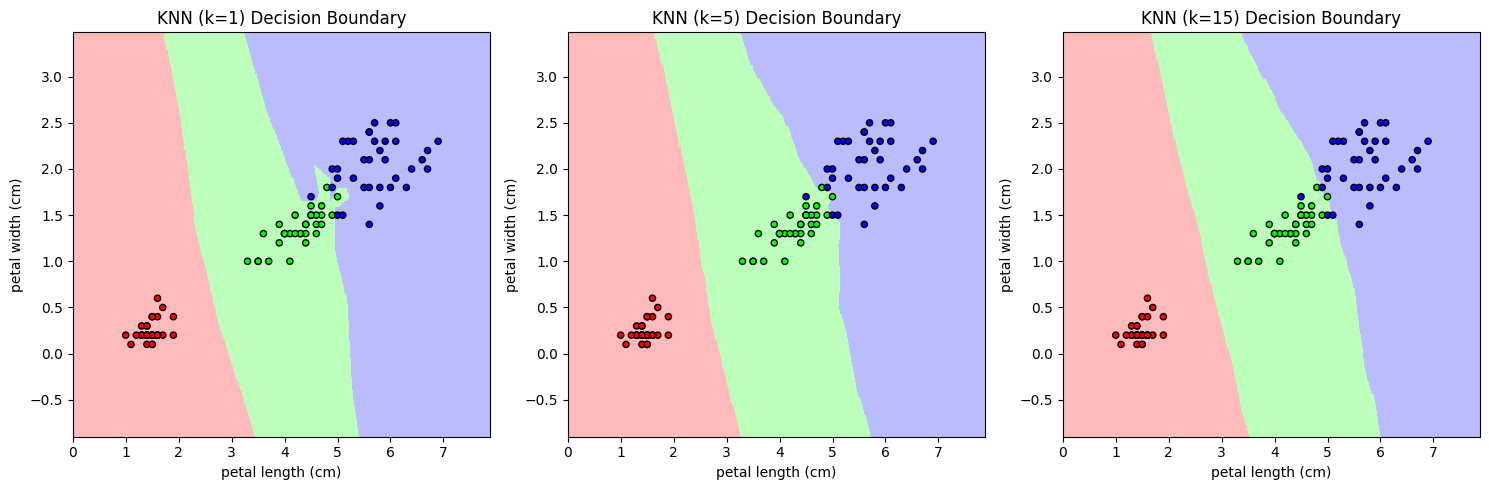

In [24]:
k_values = [1, 5, 15] # Experiment with different K values

plt.figure(figsize=(15, 5))

for i, k in enumerate(k_values):
    ax = plt.subplot(1, len(k_values), i + 1)
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_vis, y_train_vis)
    plot_decision_boundary(X_train_vis, y_train_vis, knn, f'KNN (k={k}) Decision Boundary', ax)

plt.tight_layout()
plt.show()

In [25]:
# @title step_artifacts
num_fig = "1" # @param {type:"string"}
step = 'DecisionBoundaryVisualization'  # @param ["DataLoading", "DataExploration", "DataCleaning", "DataWrangling", "DataVisualization", "DataSplitting", "ModelDevelopment", "ModelOptimization", "ModelEvaluation", "Summary", "DecisionBoundaryVisualization"] {type:"string"}
# Assume upload_plt_to_gcs function is available in the environment if needed.
# upload_plt_to_gcs(num_fig, step, plt)

## Section 13: Lab Exercise

### Question 1:
Explain the purpose of `random_state` in `train_test_split` and why it's important for reproducibility.


The `random_state` parameter in `train_test_split` controls the shuffling applied to the data before splitting. It's important for reproducibility because setting it to a fixed integer ensures that the same random split is generated every time the code is run. Without a `random_state`, each execution would result in a different train/test split, leading to potentially different model performances and making it difficult to compare results consistently.

### Question 2:
Describe how the K-Nearest Neighbors (KNN) algorithm classifies a new data point. What role does 'K' play in this process?


The K-Nearest Neighbors (KNN) algorithm classifies a new data point by finding the `K` closest data points (neighbors) in the training set based on a distance metric (e.g., Euclidean distance). The new data point is then assigned the class label that is most common among its `K` nearest neighbors (majority vote).

'K' plays a crucial role as it determines the number of neighbors considered for the majority vote. A small `K` makes the model sensitive to noise and local patterns (high variance), while a large `K` makes the model smoother and less sensitive to individual data points, potentially oversmoothing the decision boundary and increasing bias.

### Question 3:
Based on the confusion matrix and classification report, which class (species) does the model struggle with the most, if any? Provide reasoning.


Based on the confusion matrix and classification report:

**Confusion Matrix:**
```
[[18  0  0]
 [ 0  9  1]
 [ 0  0 17]]
```
**Classification Report:**
```
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        18
  versicolor       1.00      0.90      0.95        10
   virginica       0.94      1.00      0.97        17
```

The model struggles the most with the **versicolor** class.

**Reasoning:**
*   **Recall for Versicolor:** The recall for 'versicolor' is 0.90, which is lower than for 'setosa' (1.00) and 'virginica' (1.00). This means 10% of actual 'versicolor' samples were incorrectly classified.
*   **Confusion Matrix:** Looking at the confusion matrix, there is one instance where a 'versicolor' (true label) was predicted as 'virginica'. This is the `1` in the second row, third column (`[1]`) of the confusion matrix. All other classes have perfect recall (0 misclassifications from their true class).

### Question 4:
How would changing the value of 'K' (number of neighbors) affect the model's bias-variance tradeoff? Provide an example.


Changing the value of 'K' directly impacts the bias-variance tradeoff in a KNN model:

*   **Small K (e.g., K=1):**
    *   **Low Bias:** The model is highly flexible and captures local patterns closely, leading to low bias. It fits the training data very well.
    *   **High Variance:** It is highly sensitive to noise or outliers in the training data. A single noisy neighbor can significantly alter a prediction, leading to high variance and potentially overfitting.
    *   **Example:** If K=1, a data point is classified solely by its single nearest neighbor. If that neighbor is an outlier or mislabeled, the prediction will be wrong.

*   **Large K (e.g., K=20):**
    *   **High Bias:** The model becomes smoother and considers a larger neighborhood. This averages out local irregularities, leading to higher bias (it might miss subtle patterns).
    *   **Low Variance:** It is less sensitive to individual noisy data points or outliers, as their influence is diluted among many neighbors, leading to lower variance and potentially underfitting.
    *   **Example:** If K is very large, the decision boundary becomes very smooth, potentially classifying distinct clusters of data points into the same class if the majority of the overall dataset leans that way, even if locally, they are closer to another class.

In essence, there's a sweet spot for K. A good K balances the tradeoff, reducing both bias and variance to achieve optimal generalization performance.